# 02: Annotate celltypes using decoupler

In [1]:
import spatialdata as sd
import spatialdata_plot
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import scanpy as sc
import scanpy.external as sce
import matplotlib.pyplot as plt
import anndata as ad
import rapids_singlecell as rsc

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml_rsc/lib/python3.10/importlib/__init__.py:126: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  return _bootstrap._gcd_import(name[level:], package, level)


ModuleNotFoundError: No module named 'dask.dataframe.dask_expr'

In [3]:
proj_dir = Path("/lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure")
data_dir = proj_dir / Path("data")

## prepare the data

In [4]:
sdata_sample1 = sd.read_zarr(data_dir / "xenium_sample1.zarr")
sdata_sample2 = sd.read_zarr(data_dir / "xenium_sample2.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04


In [5]:
sdata_sample1["table"].obs["sample"] = "sample1"
sdata_sample2["table"].obs["sample"] = "sample2"

## preproc

In [6]:
adata_gexp_raw = ad.concat([sdata_sample1["table"], sdata_sample1["table"]])

adata_gexp_raw.obs_names_make_unique()

adata_gexp_raw.var["mt"] = adata_gexp_raw.var_names.str.startswith("MT-")
adata_gexp_raw.var["ribo"] = adata_gexp_raw.var_names.str.startswith(("RPS", "RPL"))
adata_gexp_raw.var["hb"] = adata_gexp_raw.var_names.str.contains("^HB[^(P)]")

sc.pp.calculate_qc_metrics(
    adata_gexp_raw,
    qc_vars=["mt", "ribo", "hb"],
    percent_top=[],  
    inplace=True,
    log1p=True,
)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


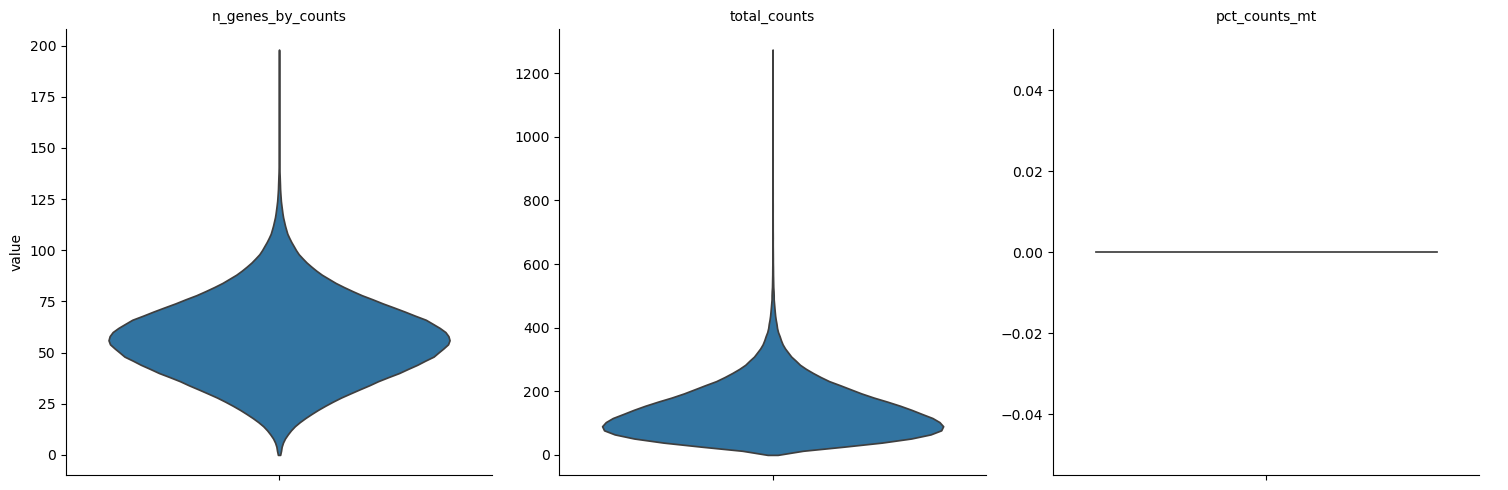

In [7]:
sc.pl.violin(
    adata_gexp_raw,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.2,
    multi_panel=True,
    stripplot=False, # too many points to see anything
)

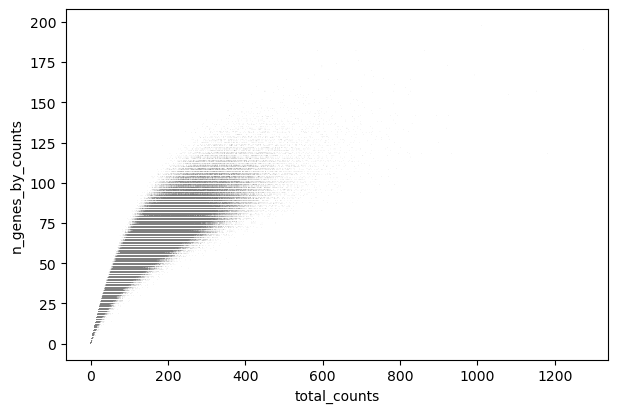

In [8]:
sc.pl.scatter(adata_gexp_raw, "total_counts", "n_genes_by_counts")

In [36]:
print(adata_gexp_raw.shape)

# not doing this step because our resulting data is then out of sync when we merge with morphology
# sc.pp.filter_cells(adata_gexp_raw, min_genes=100) # only cells with at least 100 genes expressed

sc.pp.filter_genes(adata_gexp_raw, min_cells=100) # only genes expressed in at least 100 cells
print(adata_gexp_raw.shape)

(1149054, 380)
(1149054, 380)


In [9]:
adata_gexp_raw.layers["counts"] = adata_gexp_raw.X.copy()
sc.pp.normalize_total(adata_gexp_raw)
sc.pp.log1p(adata_gexp_raw)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:234: UserWarning: Some cells have zero counts
  warn(UserWarning("Some cells have zero counts"))


In [10]:
# drops to 100 genes, do we want that?

sc.pp.highly_variable_genes(adata_gexp_raw, flavor="seurat", batch_key="sample")
adata_gexp_hvg = adata_gexp_raw[:, adata_gexp_raw.var["highly_variable"]].copy()
adata_gexp_hvg

AnnData object with n_obs × n_vars = 1149054 × 107
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'log1p', 'hvg'
    obsm: 'spatial'
    layers: 'counts'

In [11]:
sc.tl.pca(adata_gexp_hvg)
sce.pp.harmony_integrate(adata_gexp_hvg, key="sample", max_iter_harmony=20)

2025-05-17 21:18:18,392 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-05-17 21:19:41,372 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-05-17 21:19:46,329 - harmonypy - INFO - Iteration 1 of 20


In [ ]:
sc.pp.neighbors(adata_gexp_raw, use_rep="X_pca_harmony")
sc.tl.umap(adata_gexp_raw)
sc.tl.leiden(adata_gexp_raw)

In [ ]:
sc.pl.umap(
    adata_gexp_raw,
    color=["sample", "leiden"],
    wspace=0.4,
    title=["sample", "leiden"],
    frameon=False,
)